<a href="https://colab.research.google.com/github/ayeshaazahidd0-stack/Digital-Image-Processing/blob/main/DIP_Lab2_AyeshaZahid_pdf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LAB 2 — Pixel/Channel Ops & Color Models (HSV/LAB/BGR↔RGB)

In [ ]:
!pip install -q opencv-python
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload ONE color image (jpg/png)
uploaded = files.upload()
fname = list(uploaded.keys())[0]

# Read image in BGR (OpenCV default)
img_bgr = cv2.imread(fname)
assert img_bgr is not None,"Image failed to load. Please upload a color photo."
assert img_bgr.ndim == 3 and img_bgr.shape[2] == 3,"Please upload a COLOR image (3 channels).";

h, w = img_bgr.shape[:2]
print("Loaded:", fname, "| Shape (H,W,C):", img_bgr.shape, "| Dtype:",

img_bgr.dtype)

Saving cozy-cafe-bistro-with-blurred-background-and-wooden-montage-generative-ai-photo.jpg to cozy-cafe-bistro-with-blurred-background-and-wooden-montage-generative-ai-photo.jpg
Loaded: cozy-cafe-bistro-with-blurred-background-and-wooden-montage-generative-ai-photo.jpg | Shape (H,W,C): (700, 1249, 3) | Dtype: uint8


Task 1 — Café Blackboard: V-only Brightening (HSV)

Average V before: 54.44
Average V after: 79.27
Original Image:


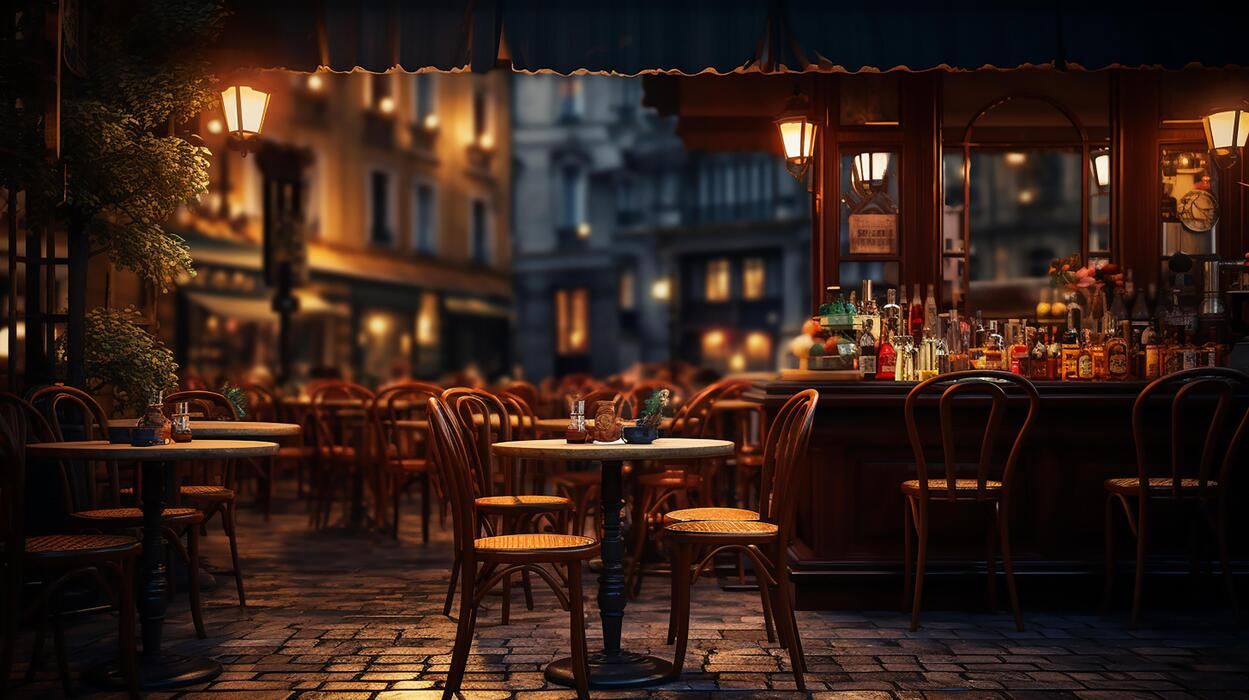

Brighter Image (V + 25):


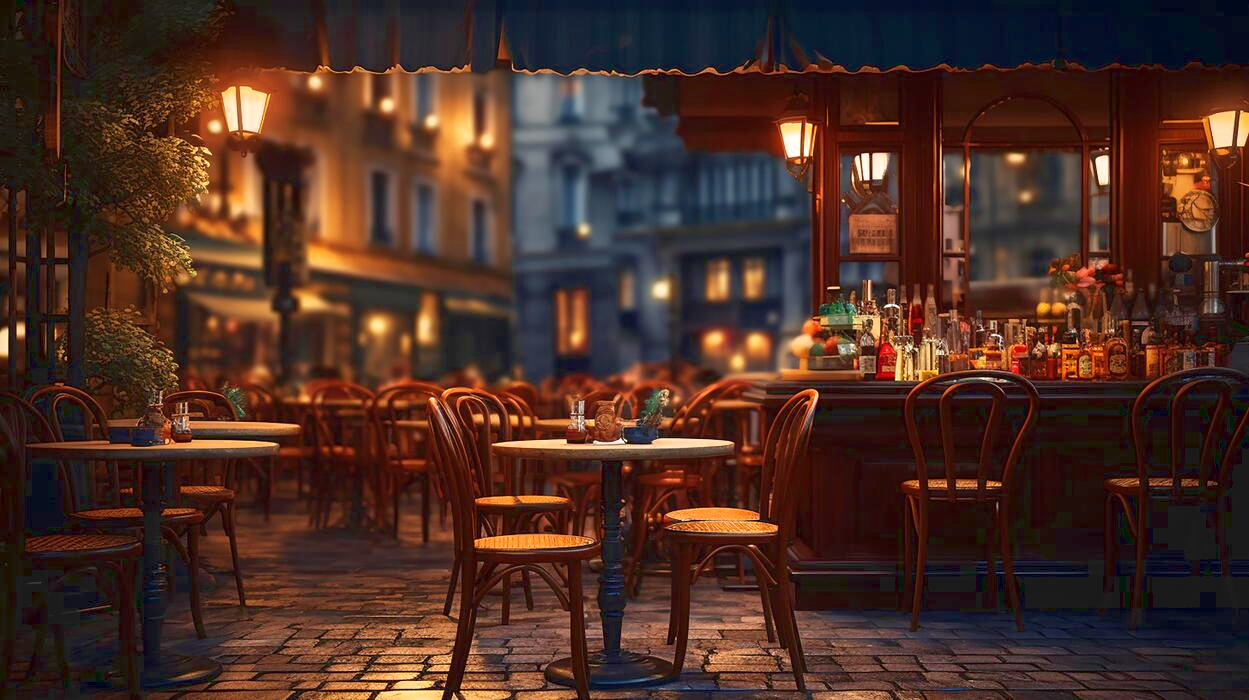

In [ ]:
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(img_hsv)
cv2_imshow(H)

cv2_imshow(S)
cv2_imshow(V)
print("Hue range (OpenCV):", int(H.min()), "to", int(H.max()), "(0..179)")
bright_hsv = img_hsv.copy()
bright_hsv[:, :, 2] = cv2.add(bright_hsv[:, :, 2], 40) # safe add, stops at 255
bright_bgr = cv2.cvtColor(bright_hsv, cv2.COLOR_HSV2BGR)
cv2_imshow(bright_bgr)

Task 2 — Museum Look: Controlled Desaturation (HSV–S)

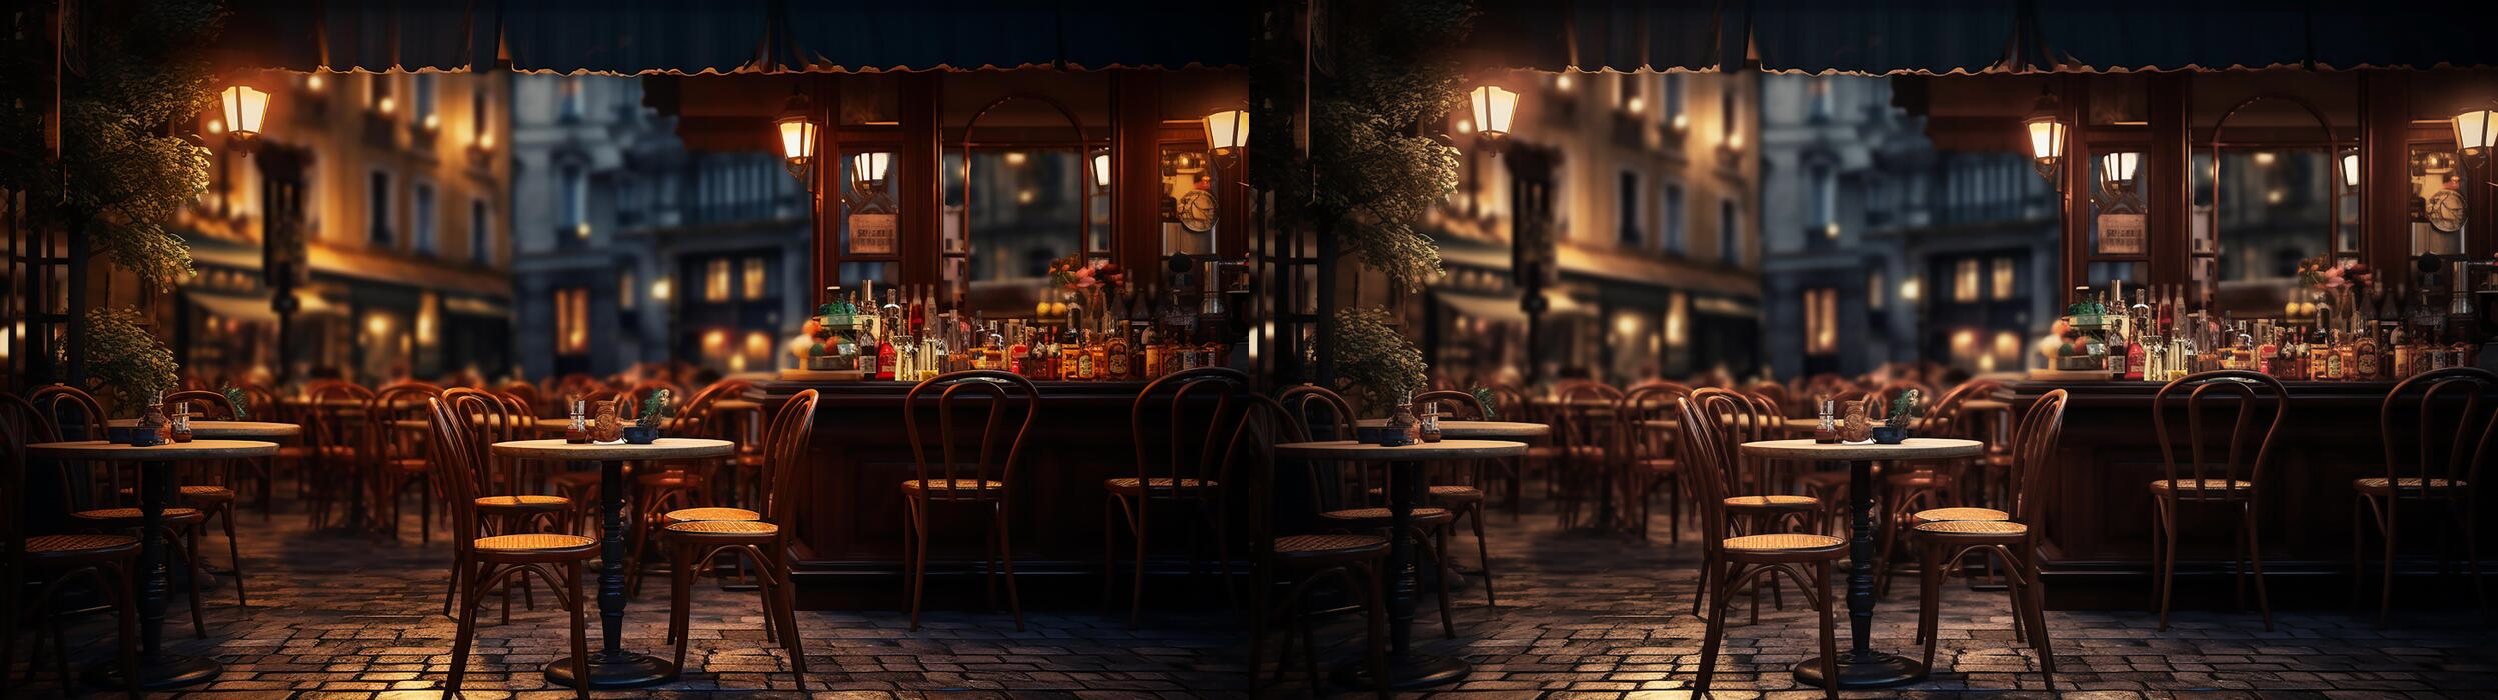

The Saturation (S) channel determines color intensity: higher values yield highly vibrant colors, while lower values fade them toward grayscale, controlling color strength.


In [ ]:
# 1. Convert BGR to HSV
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(img_hsv)

# 2. Set S <- 0.75 * S (round & clip to [0, 255])
S_calm = np.clip(np.round(S * 0.75), 0, 255).astype(np.uint8)

# 3. Leave H, V as is and convert back to BGR
hsv_calm = cv2.merge([H, S_calm, V])
bgr_calm = cv2.cvtColor(hsv_calm, cv2.COLOR_HSV2BGR)

# 4. Compare side-by-side
comparison = np.hstack((img_bgr, bgr_calm))
cv2_imshow(comparison)

# 5. One-liner explanation
print("The Saturation (S) channel determines color intensity: higher values yield highly vibrant colors, while lower values fade them toward grayscale, controlling color strength.")

Task 3 — Cooler Interior: Small Hue Shift

In [ ]:
# Upload a new color photo for the living-room cooling task
uploaded_task3 = files.upload()
fname_task3 = list(uploaded_task3.keys())[0]

# Read image in BGR (and update img_bgr for subsequent tasks)
img_bgr = cv2.imread(fname_task3)
assert img_bgr is not None, "Image failed to load. Please upload a color photo."
assert img_bgr.ndim == 3 and img_bgr.shape[2] == 3, "Please upload a COLOR image (3 channels)."

print("Uploaded and loaded:", fname_task3, "| Shape:", img_bgr.shape)

Saving images.jpeg to images.jpeg
Uploaded and loaded: images.jpeg | Shape: (275, 183, 3)


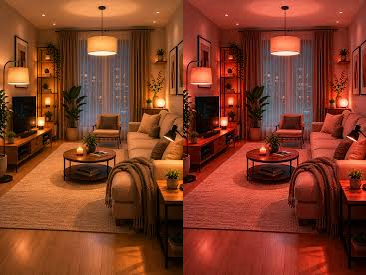

Note: The valid Hue (H) range in OpenCV is 0 to 179, where each unit corresponds to 2 degrees on the standard 360-degree color wheel.


In [ ]:
# 1. Convert BGR to HSV
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(img_hsv)

# 2. Apply Hue shift -8 (wrap in OpenCV's [0, 179] range)
# We cast to int16 to prevent underflow, apply the shift, modulo 180, and cast back to uint8
H_cool = ((H.astype(np.int16) - 8) % 180).astype(np.uint8)

# 3. Merge back with S, V unchanged and convert to BGR
hsv_cool = cv2.merge([H_cool, S, V])
bgr_cool = cv2.cvtColor(hsv_cool, cv2.COLOR_HSV2BGR)

# 4. Show the result side-by-side with the original image
comparison_cool = np.hstack((img_bgr, bgr_cool))
cv2_imshow(comparison_cool)

# 5. Output notes including the valid H range
print("Note: The valid Hue (H) range in OpenCV is 0 to 179, where each unit corresponds to 2 degrees on the standard 360-degree color wheel.")

Task 4 — Channel Storyboard + Rebuild (Split/Merge)

Saving urban street.jpg to urban street.jpg
Blue Channel Grayscale:


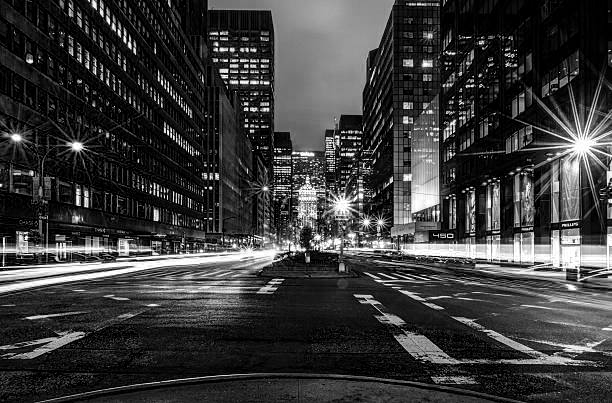

Green Channel Grayscale:


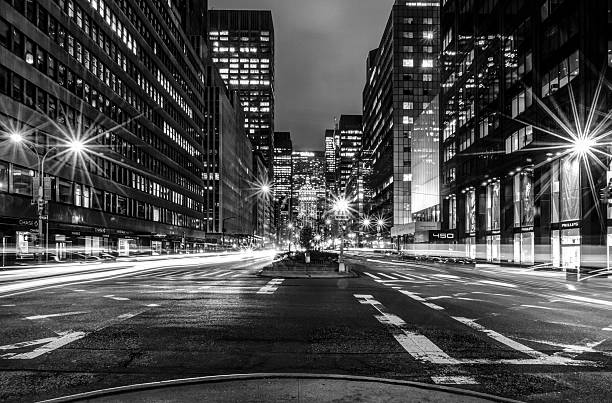

Red Channel Grayscale:


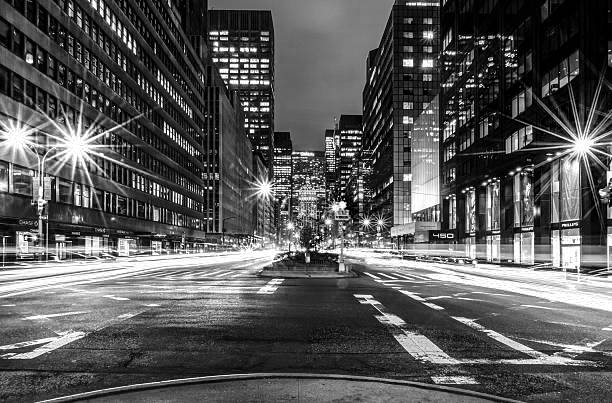

Reconstructed Color Image:


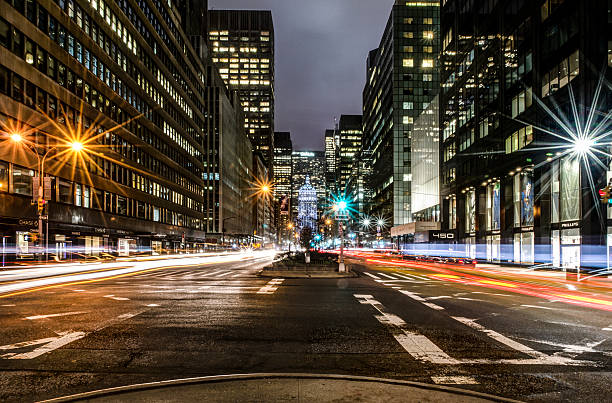


--- Channel Contributions Guide for Designers ---
- Blue Channel (B): Bright pixels represent regions with high blue intensity, such as blue skies, blue vehicles, or signs.
- Green Channel (G): Bright pixels indicate rich green content, commonly found in urban foliage, trees, or green traffic lights.
- Red Channel (R): Bright pixels highlight strong red information, such as brick buildings, brake lights, or red stop signs.


In [ ]:
# 1. Upload new urban street photo
uploaded_task4 = files.upload()
fname_task4 = list(uploaded_task4.keys())[0]
img_bgr = cv2.imread(fname_task4)
assert img_bgr is not None, "Image failed to load."

# 2. Split into B, G, R channels
b, g, r = cv2.split(img_bgr)

# 3. Show each single-channel view as a grayscale image
print("Blue Channel Grayscale:")
cv2_imshow(b)
print("Green Channel Grayscale:")
cv2_imshow(g)
print("Red Channel Grayscale:")
cv2_imshow(r)

# 4. Rebuild the color image by merging them back
reconstructed_bgr = cv2.merge([b, g, r])
print("Reconstructed Color Image:")
cv2_imshow(reconstructed_bgr)

# 5. Explanatory bullets for the junior designer
print("\n--- Channel Contributions Guide for Designers ---")
print("- Blue Channel (B): Bright pixels represent regions with high blue intensity, such as blue skies, blue vehicles, or signs.")
print("- Green Channel (G): Bright pixels indicate rich green content, commonly found in urban foliage, trees, or green traffic lights.")
print("- Red Channel (R): Bright pixels highlight strong red information, such as brick buildings, brake lights, or red stop signs.")

Task 5 — LAB: Lightness &amp; Mild Cast Fix (L, a, b)

Saving photoshot.jpeg to photoshot.jpeg
Comparison: Original (Left) vs. L-Only Brightened (Center) vs. Color-Corrected (Right)


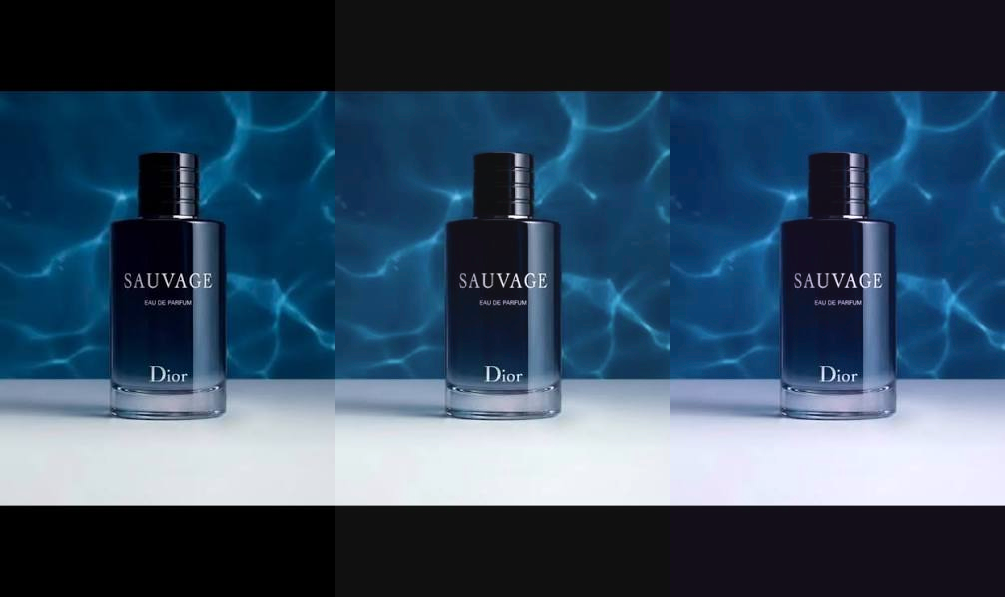

In [ ]:
# 1. Upload a product photo shot under fluorescent light
uploaded_task5 = files.upload()
fname_task5 = list(uploaded_task5.keys())[0]
img_bgr = cv2.imread(fname_task5)
assert img_bgr is not None, "Image failed to load."

# 2. Convert BGR to LAB color space and split channels
img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
L, A, B = cv2.split(img_lab)

# 3. Apply L-only gentle brightening (L +12, clipped to uint8 [0, 255])
L_bright = np.clip(cv2.add(L, 12), 0, 255)
lab_l_only = cv2.merge([L_bright, A, B])
bgr_l_only = cv2.cvtColor(lab_l_only, cv2.COLOR_LAB2BGR)

# 4. Correct the cast: tweak 'a' (+4 to shift green towards magenta) and 'b' (-6 to shift yellow towards blue)
A_tweaked = np.clip(cv2.add(A, 4), 0, 255)
B_tweaked = np.clip(cv2.subtract(B, 6), 0, 255)
lab_tweaked = cv2.merge([L_bright, A_tweaked, B_tweaked])
bgr_tweaked = cv2.cvtColor(lab_tweaked, cv2.COLOR_LAB2BGR)

# 5. Display side-by-side comparison (Original, L-only brightened, a/b color-corrected)
comparison_lab = np.hstack((img_bgr, bgr_l_only, bgr_tweaked))
print("Comparison: Original (Left) vs. L-Only Brightened (Center) vs. Color-Corrected (Right)")
cv2_imshow(comparison_lab)